![Banner](../images/09_02_banner_rs_optical.png)


# Introduction to Optical Satellite Images

Optical satellites photograph the Earth in sunlight, in visible, near-infrared and shortwave-infrared light.

Seven notebooks take an optical image from the sensor to a corrected time series.

- **Introduction to Optical Satellite Images.** This notebook. How optical sensors work, what limits their images, what they are used for, and where to get them, open or commercial.
- **Preprocessing of Optical Images.** Haze, terrain shading, clouds, mismatched resolutions and small geometric offsets, and a measure of how well each correction works.
- **MODIS: Global Monitoring Every Day.** Terra and Aqua, 36 bands every one to two days, turned into analysis-ready time series with `geolattice.rsense`.
- **Landsat: Half a Century of Earth Observation.** Collection 2 from Landsat 1 in 1972 to Landsat 9, at 30 m: scale factors, QA, composites, indices, surface temperature, and multi-decade change.
- **Sentinel-2: Red Edge, 10 m and Five-Day Revisits.** Thirteen bands and three red-edge bands, on a two-and-a-half-year time series.
- **Sentinel-3: Ocean Colour, Surface Temperature and Altimetry.** OLCI, SLSTR and SRAL, with real products from Microsoft Planetary Computer.
- **Sentinel-5P and Sentinel-5: Mapping Air Pollution from Orbit.** TROPOMI columns of NO2, SO2, CO, CH4 and HCHO over Bangladesh and New York State.



## Overview

They are the most widely used source of Earth observation data, from free global archives such as Landsat and Sentinel-2 to commercial constellations that resolve individual cars. This notebook introduces the optical chapter (07_02): how optical sensors work, what limits their images, what they are used for, and where to get them, open or commercial. Notebook 07_01_00 covered the physics of radiation and reflectance; here we focus on the **sensors and the data**.


## Core concepts

### Learning objectives

1. Explain how optical imaging sensors (whiskbroom, pushbroom and frame cameras) form an image,
   and what panchromatic, multispectral and hyperspectral mean.
2. Relate ground sampling distance, swath, revisit, viewing angle, signal-to-noise ratio and
   quantization to what an image can show.
3. Describe the processing chain from Level-0 counts to analysis-ready surface reflectance, and
   the main limitations of optical data (clouds, shadows, illumination).
4. Match applications to resolution classes and sensors.
5. Choose between open and commercial optical data, and know where to obtain each.
6. Quantify the effect of pixel size on a real landscape using a commercial 1.2 m image and
   open Sentinel-2 and Landsat data.

### Contents

1. What makes an image "optical"
2. How optical sensors form an image
3. Image quality: resolution, geometry and radiometry
4. From photons to analysis-ready data
5. Limitations of optical data
6. Resolution classes and applications
7. Open optical data
8. Commercial optical data
9. Choosing data and getting access
10. Hands-on: a commercial 8-band image
11. Hands-on: pixel size and mixed pixels
12. Hands-on: open Sentinel-2 and Landsat over the same place (live)
13. Summary, exercises and references


## What makes an image "optical"

An **optical** sensor records electromagnetic energy with lenses or mirrors and detectors, in
the part of the spectrum where the Sun provides the illumination:

| Region | Wavelength | What the sensor records |
|---|---|---|
| Visible (VIS) | 0.40-0.70 µm | Reflected sunlight; what our eyes see |
| Near infrared (NIR) | 0.70-1.3 µm | Reflected sunlight; strongly reflected by leaves |
| Shortwave infrared (SWIR) | 1.3-2.5 µm | Reflected sunlight; sensitive to water in leaves and soils, and to minerals |
| Thermal infrared (TIR) | 8-14 µm | Energy *emitted* by the surface (usually treated separately as thermal remote sensing) |

Optical remote sensing is **passive**: the sensor only listens. Two consequences follow. Images
exist only in daylight (except thermal and night-light sensors), and clouds block the view,
because cloud droplets scatter visible and infrared light strongly. Radar (chapter 07_03) is the
active, cloud-penetrating complement.

What an optical sensor measures in each band is the **radiance** reaching it. After calibration
and atmospheric correction this becomes the surface **reflectance**, the fraction of sunlight
the surface reflects, and the shape of reflectance across bands (the spectral signature)
identifies materials (notebook 07_01_00, the *How optical sensors form an image* and *Commercial optical data* sections).


## How optical sensors form an image

### The imaging chain

Light from the ground passes through a **telescope** (mirrors or lenses), is split into
wavelength bands by **filters**, prisms or gratings, and falls on **detectors** that convert
photons into electrons. The electronics amplify and digitize the signal into **digital numbers
(DN)**. Detector materials depend on the wavelength:

* **Silicon** (CCD or CMOS) for visible and NIR light, up to about 1 µm.
* **InGaAs** or **HgCdTe** for SWIR.
* **HgCdTe** or microbolometers for thermal infrared.

### Scanning geometries

| Design | How the image is built | Examples |
|---|---|---|
| **Whiskbroom (across-track scanner)** | A rotating mirror sweeps a few detectors from side to side while the satellite moves forward | Landsat 1-7 (MSS, TM, ETM+), MODIS, AVHRR |
| **Pushbroom (along-track scanner)** | A long line of thousands of detectors images a whole row at once; the orbit motion adds rows | Landsat 8/9 OLI, Sentinel-2 MSI, SPOT, Pléiades, WorldView |
| **Frame camera (area array)** | A 2-D detector takes a snapshot of a rectangle, like a phone camera | PlanetScope, SkySat, most UAV cameras |

Pushbroom sensors have no moving parts and dwell longer on each ground point, so they give a
higher signal-to-noise ratio than whiskbrooms. Very-high-resolution satellites add **time delay
integration (TDI)**, summing the signal of successive detector rows as the image moves across
them, to collect enough light for pixels under a metre.

### Panchromatic, multispectral and hyperspectral

| Type | Bands | Typical use |
|---|---|---|
| **Panchromatic** | One broad band (about 0.45-0.80 µm) | The sharpest detail; combined with multispectral bands by **pan-sharpening** |
| **Multispectral** | 4-15 broad bands | Land cover, vegetation, water: most operational mapping |
| **Superspectral** | 15-40 narrower bands | MODIS, Sentinel-3 OLCI: ocean colour, atmosphere |
| **Hyperspectral** | 100-400 contiguous narrow bands | Minerals, pigments, water quality, crop traits (EnMAP, PRISMA, EMIT) |

Each band is defined by its **spectral response function**, the sensitivity of the detector at
each wavelength. Two sensors with "red" bands of different widths and centres record different
values over the same surface, which is why data from different sensors must be **harmonized**
before they are combined (for example the Harmonized Landsat Sentinel-2 product).


## Image quality: resolution, geometry and radiometry

### Ground sampling distance and swath

The **ground sampling distance (GSD)** is the distance between pixel centres on the ground. For a
detector of pitch $p$, a telescope of focal length $f$ and an orbit altitude $H$, looking
straight down (nadir),

$$\text{GSD} = \frac{p\,H}{f} = H \cdot \text{IFOV},$$

where IFOV is the instantaneous field of view of one detector (in radians). The **swath** is
the width imaged on the ground, roughly GSD × number of detectors across track. With a fixed
number of detectors, a finer GSD means a narrower swath, and a narrower swath means a longer
time before the satellite passes over the same place again.

**Viewing angle.** Commercial satellites point their telescope off nadir to image a target
sooner. At an off-nadir angle θ the across-track GSD grows roughly as $\text{GSD}_0/\cos^2\theta$
and the along-track GSD as $\text{GSD}_0/\cos\theta$, and tall objects lean (relief displacement).
"0.3 m" imagery is 0.3 m only near nadir.

**GSD is not resolution.** Optical blur, detector size, satellite motion and atmospheric
scattering spread each point over neighbouring pixels. The **modulation transfer function (MTF)**
measures how much contrast survives at each spatial frequency. As a rule of thumb, an object
must span two to three pixels to be reliably identified.

### Radiometric quality

* **Quantization** (radiometric resolution): Landsat 8 records 12 bits (4,096 levels),
  Landsat 9 and many commercial sensors 11-14 bits.
* **Signal-to-noise ratio (SNR)**: how far the signal stands above detector and electronic
  noise. It is critical over dark targets such as water, where most of the signal is atmosphere.
* **Calibration**: on-board lamps, solar diffusers, lunar views and ground "pseudo-invariant"
  desert sites keep DNs traceable to radiance over a mission's lifetime.

### Orbits and revisit

Most land-imaging satellites fly **sun-synchronous** polar orbits at 450-800 km, crossing the
equator at the same local solar time on every pass (about 10:00-10:30 for Landsat and
Sentinel-2), so illumination is comparable between dates. The **repeat cycle** is the time to
return to exactly the same orbit track (16 days for one Landsat); the **revisit time** is how
often a place can be imaged at all, which pointing and constellations shorten (daily or
better for PlanetScope and the WorldView fleet). Geostationary weather satellites (GOES,
Himawari, Meteosat) stare at one hemisphere every 5-15 minutes, at 0.5-2 km pixels.

The chart below places common optical sensors on the two axes that define most choices.
Values are approximate nadir figures for the main multispectral product.


**Installation.** This notebook needs installation option 5 (core, spatial analysis, spatial statistics, geostatistics and remote sensing): `pip install "geolattice[remote-sensing]"`. See "Installation options" in the GeoLattice README.

In [1]:
# This cell prepares the notebook. Every later code cell reads images, builds
# tables or draws plots, so the libraries are imported once, here.
#
# 1. Show matplotlib figures inside the notebook, and hide warnings that are
#    not errors.
# 2. Import NumPy (arrays), pandas (tables), xarray (labelled rasters),
#    GeoPandas (the class-point shapefile), rasterio (windowed GeoTIFF reads)
#    and matplotlib.
# 3. Import `geolattice` and `geolattice.rsense` as `rs`. `rs` is the remote-sensing
#    toolbox used below: `rs.read`, `rs.viz`, `rs.optical`, `rs.classify`.
# 4. Silence harmless GDAL messages about unusual TIFF tags, set a slightly
#    sharper plot style, and print the package versions and the compute
#    backend (`cpu` or a GPU name).

%matplotlib inline
import warnings  # warning control
warnings.filterwarnings("ignore", category=UserWarning)  # hide library notices; real errors still print

import os  # environment variables
import time                       # used later to time the live Sentinel-2 / Landsat download
from pathlib import Path          # file paths that work on any operating system

import numpy as np                # numeric arrays: pixel blocks, percentiles, masks
import pandas as pd               # small tables: sensors, bands, class signatures
import xarray as xr               # multi-band images with coordinates
import geopandas as gpd           # read the land-cover point labels (a shapefile)
import rasterio                   # open GeoTIFFs and read a downsampled preview
import matplotlib.pyplot as plt  # figures

import geolattice  # GeoLattice
import geolattice.rsense as rs         # optical helpers used in every hands-on section

# Commercial TIFFs often carry non-standard tags. GDAL prints a notice for each
# one. Sending that log to /dev/null keeps the notebook output to the numbers
# we actually print. This does not change the pixel values.
rasterio.Env(CPL_LOG="/dev/null").__enter__()
# figure resolution and a light grid
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
# versions and backend
print("geolattice", geolattice.__version__, "| geolattice.rsense", rs.__version__, "| backend:", rs.get_backend())

geolattice 0.3.11 | geolattice.rsense 0.2.0.dev0 | backend: cpu


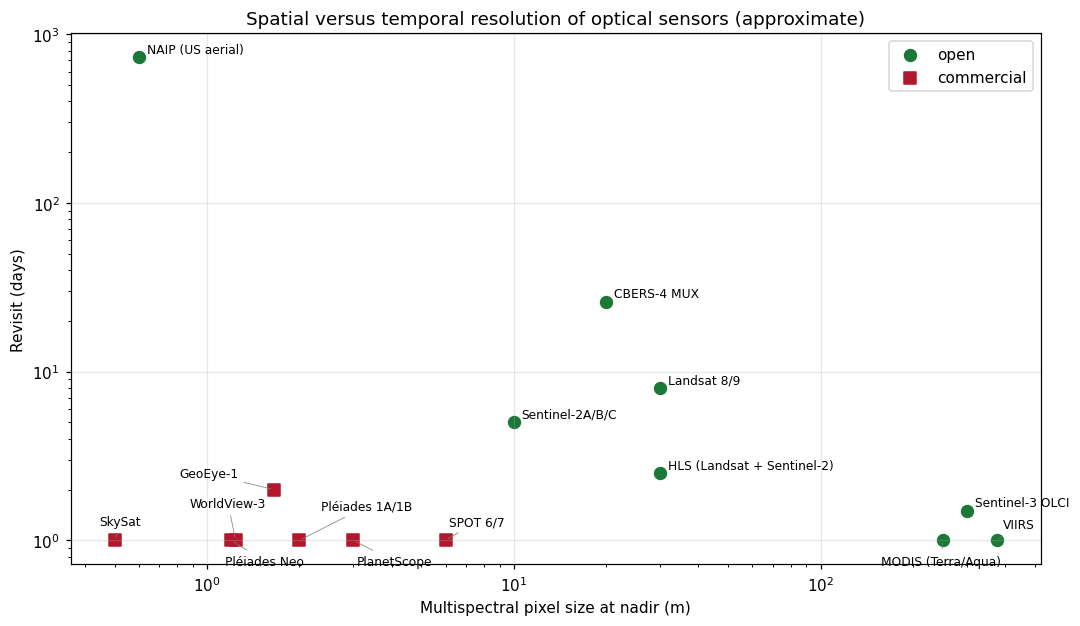

In [2]:
# This cell compares optical sensors by pixel size and revisit. That trade-off
# is the point of the section above: a finer pixel usually means a narrower
# swath, so the satellite takes longer to see the same place again. Many small
# satellites (a constellation) are how commercial missions break that trade-off.
#
# 1. Build a table with one row per mission:
#    - sensor name
#    - multispectral ground sampling distance (GSD) in metres, at nadir
#    - typical revisit in days
#    - whether the archive is open or commercial
# 2. Scatter pixel size (x) against revisit (y). Both axes are logarithmic, so
#    1 m, 10 m and 100 m are evenly spaced and the coarse daily sensors and the
#    fine sensors fit on one figure.
# 3. Open missions are green circles; commercial missions are red squares.
# 4. A few names would land on top of each other, so `offsets` nudges those labels.

sensors = pd.DataFrame([
    # name, multispectral GSD (m), revisit (days), access
    # Coarse, near-daily, open: whole-Earth monitoring.
    ("MODIS (Terra/Aqua)", 250, 1, "open"), ("VIIRS", 375, 1, "open"), ("Sentinel-3 OLCI", 300, 1.5, "open"),
    # Medium resolution, open: the workhorses for land cover and change.
    ("Landsat 8/9", 30, 8, "open"), ("Sentinel-2A/B/C", 10, 5, "open"), ("HLS (Landsat + Sentinel-2)", 30, 2.5, "open"),
    ("CBERS-4 MUX", 20, 26, "open"), ("NAIP (US aerial)", 0.6, 730, "open"),
    # Fine pixels and a short revisit, sold rather than given away.
    ("PlanetScope", 3, 1, "commercial"), ("SkySat", 0.5, 1, "commercial"), ("SPOT 6/7", 6, 1, "commercial"),
    ("Pléiades 1A/1B", 2, 1, "commercial"), ("Pléiades Neo", 1.2, 1, "commercial"),
    ("WorldView-3", 1.24, 1, "commercial"), ("GeoEye-1", 1.65, 2, "commercial"),
], columns=["sensor", "gsd_m", "revisit_days", "access"])

# Nudge only the names that would collide. The pair is an offset in points
# (positive x is right, positive y is up). Names not listed get a small default.
offsets = {"SkySat": (-10, 10), "WorldView-3": (-30, 22), "Pléiades Neo": (-4, -16), "Pléiades 1A/1B": (14, 20), "GeoEye-1": (-62, 8),
           "PlanetScope": (2, -16), "SPOT 6/7": (2, 10), "MODIS (Terra/Aqua)": (-40, -16), "VIIRS": (4, 8)}
fig, ax = plt.subplots(figsize=(10, 5.8))  # one panel
# Plot the two access classes separately so each gets its own colour, marker and legend entry.
for acc, mk, col in [("open", "o", "#1b7837"), ("commercial", "s", "#b2182b")]:
    s = sensors[sensors.access == acc]  # sensors of this access class
    # pixel size against revisit time
    ax.scatter(s.gsd_m, s.revisit_days, marker=mk, s=60, color=col, label=acc)
    for _, r in s.iterrows():  # label each sensor
        # textcoords="offset points" places the label relative to the dot, not in data units.
        # A short grey stem is drawn only for the labels we moved, so you can see which dot they belong to.
        ax.annotate(r.sensor, (r.gsd_m, r.revisit_days), xytext=offsets.get(r.sensor, (5, 3)), textcoords="offset points",
                    fontsize=8, arrowprops=dict(arrowstyle="-", lw=0.5, color="grey") if r.sensor in offsets else None)
ax.set_xscale("log"); ax.set_yscale("log")  # log scales: 0.5 m and 375 m both stay readable
ax.set_xlabel("Multispectral pixel size at nadir (m)"); ax.set_ylabel("Revisit (days)")  # axis labels
ax.set_title("Spatial versus temporal resolution of optical sensors (approximate)")  # title
ax.legend(); plt.tight_layout(); plt.show()  # legend, arrange and draw

Open missions sit to the right (10 m and coarser) and trade detail for free, systematic, global
coverage. Commercial constellations fill the lower left: fine pixels *and* frequent revisits,
achieved with many satellites and agile pointing, at a price. NAIP shows that aerial
programmes can be both open and very fine, but only every few years and only for one country.

### Where the bands are

Band sets differ between sensors. Commercial sensors often add a **coastal/aerosol** band
(water penetration, haze), a **yellow** band and one or two **red-edge** and **NIR** bands. The
chart shows nominal band centres and widths from the operators' specifications.


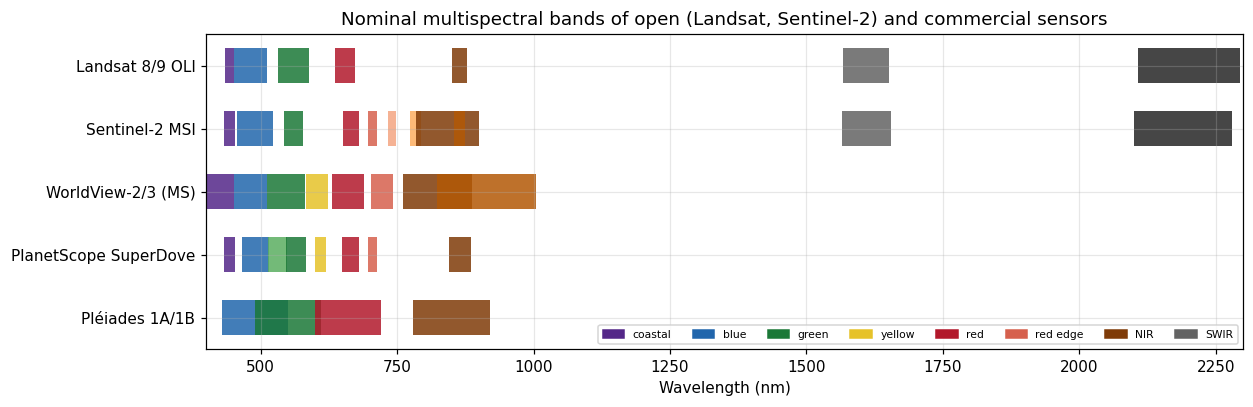

In [3]:
# This cell draws where each sensor's bands sit along the spectrum.
# A band is a slice of wavelengths: a centre (nm) and a width (nm). Each
# horizontal bar runs from centre − width/2 to centre + width/2, so a wide
# bar is a broad band and a narrow bar is a tight one.
#
# 1. List nominal centres and widths for Landsat 8/9 OLI, Sentinel-2 MSI,
#    WorldView-2/3 multispectral, PlanetScope SuperDove and Pléiades.
# 2. Colour each bar by spectral region (coastal, blue, green, yellow, red,
#    red edge, NIR, SWIR). The same colour means the same kind of light, so
#    you can compare sensors at a glance.
# 3. One row per sensor. The open missions are the rows that continue into
#    SWIR (grey bars past about 1600 nm). Most commercial rows stop in the NIR.

bands = pd.DataFrame([
    # sensor, band name, centre wavelength (nm), band width (nm)
    ("Landsat 8/9 OLI", "Coastal", 443, 16), ("Landsat 8/9 OLI", "Blue", 482, 60), ("Landsat 8/9 OLI", "Green", 561, 57),
    ("Landsat 8/9 OLI", "Red", 655, 37), ("Landsat 8/9 OLI", "NIR", 865, 28), ("Landsat 8/9 OLI", "SWIR1", 1609, 85),
    ("Landsat 8/9 OLI", "SWIR2", 2201, 187),
    ("Sentinel-2 MSI", "Coastal", 443, 20), ("Sentinel-2 MSI", "Blue", 490, 65), ("Sentinel-2 MSI", "Green", 560, 35),
    ("Sentinel-2 MSI", "Red", 665, 30), ("Sentinel-2 MSI", "RE1", 705, 15), ("Sentinel-2 MSI", "RE2", 740, 15),
    ("Sentinel-2 MSI", "RE3", 783, 20), ("Sentinel-2 MSI", "NIR", 842, 115), ("Sentinel-2 MSI", "NIR narrow", 865, 20),
    ("Sentinel-2 MSI", "SWIR1", 1610, 90), ("Sentinel-2 MSI", "SWIR2", 2190, 180),
    ("WorldView-2/3 (MS)", "Coastal", 427, 50), ("WorldView-2/3 (MS)", "Blue", 482, 60), ("WorldView-2/3 (MS)", "Green", 547, 70),
    ("WorldView-2/3 (MS)", "Yellow", 604, 40), ("WorldView-2/3 (MS)", "Red", 660, 60), ("WorldView-2/3 (MS)", "Red edge", 723, 40),
    ("WorldView-2/3 (MS)", "NIR1", 824, 125), ("WorldView-2/3 (MS)", "NIR2", 914, 180),
    ("PlanetScope SuperDove", "Coastal blue", 443, 20), ("PlanetScope SuperDove", "Blue", 490, 50),
    ("PlanetScope SuperDove", "Green I", 531, 36), ("PlanetScope SuperDove", "Green", 565, 36),
    ("PlanetScope SuperDove", "Yellow", 610, 20), ("PlanetScope SuperDove", "Red", 665, 31),
    ("PlanetScope SuperDove", "Red edge", 705, 15), ("PlanetScope SuperDove", "NIR", 865, 40),
    ("Pléiades 1A/1B", "Blue", 490, 120), ("Pléiades 1A/1B", "Green", 550, 120), ("Pléiades 1A/1B", "Red", 660, 120),
    ("Pléiades 1A/1B", "NIR", 850, 140),
], columns=["sensor", "band", "centre_nm", "width_nm"])

# One colour per band name. Close cousins (the three red-edge bands, the two NIR
# bands) share a family of colours so the legend can stay short.
palette = {"Coastal": "#542788", "Coastal blue": "#542788", "Blue": "#2166ac", "Green": "#1b7837", "Green I": "#5aae61",
           "Yellow": "#e6c229", "Red": "#b2182b", "RE1": "#d6604d", "RE2": "#f4a582", "RE3": "#fdae61", "Red edge": "#d6604d",
           "NIR": "#7f3b08", "NIR narrow": "#b35806", "NIR1": "#7f3b08", "NIR2": "#b35806", "SWIR1": "#636363", "SWIR2": "#252525"}
# dict.fromkeys keeps the first time each sensor name appears, so row order matches the table.
order = list(dict.fromkeys(bands.sensor))
fig, ax = plt.subplots(figsize=(11.5, 3.8))  # one panel
for i, s in enumerate(order[::-1]):  # reverse so the first sensor in the table is drawn as the top row
    for _, b in bands[bands.sensor == s].iterrows():  # every band of this sensor
        # barh(width, left) draws the band from its short-wavelength edge to its long-wavelength edge.
        ax.barh(i, b.width_nm, left=b.centre_nm - b.width_nm / 2, height=0.55, color=palette[b.band], alpha=0.85)
ax.set_yticks(range(len(order))); ax.set_yticklabels(order[::-1])  # sensor names on the y axis
ax.set_xlim(400, 2300); ax.set_xlabel("Wavelength (nm)")  # visible starts near 400 nm; SWIR2 ends near 2300 nm
ax.set_title("Nominal multispectral bands of open (Landsat, Sentinel-2) and commercial sensors")  # title
# The legend shows the region colours, not every band nickname (RE1, NIR narrow, ...).
handles = [plt.Rectangle((0, 0), 1, 1, color=palette[k]) for k in ["Coastal", "Blue", "Green", "Yellow", "Red", "Red edge", "NIR", "SWIR1"]]
# legend with one colour per spectral region
ax.legend(handles, ["coastal", "blue", "green", "yellow", "red", "red edge", "NIR", "SWIR"], ncol=8, fontsize=7, loc="lower right")
plt.tight_layout(); plt.show()  # arrange and draw

The open missions are the only ones in this chart with **SWIR** bands (WorldView-3 also has a
separate 3.7 m SWIR instrument, sold as its own product). SWIR is what separates moisture
conditions, burned areas, snow from cloud, and many minerals, so even users of commercial
imagery often add Landsat or Sentinel-2 for those questions.


## From photons to analysis-ready data

| Level | Content | Open examples | Commercial examples |
|---|---|---|---|
| **L0** | Raw telemetry | n/a |: |
| **L1 (radiometric)** | Calibrated DN or radiance, sensor geometry | Sentinel-2 L1B | Maxar "Basic" (1B), Airbus "Primary" |
| **L1 (geometric)** | Orthorectified with a DEM, map projection, TOA reflectance or scaled radiance | Landsat C2 Level-1, Sentinel-2 L1C | Maxar "Standard/Ortho Ready" and "Ortho", Airbus "Ortho", PlanetScope "Basic/Ortho" scenes |
| **L2** | Surface reflectance (atmosphere removed), surface temperature, cloud masks | Landsat C2 Level-2, Sentinel-2 L2A, MOD09 | PlanetScope "Surface reflectance", Maxar "Analysis-Ready Data" |
| **L3** | Composites, mosaics, gridded time series | MOD13 NDVI, HLS, Sentinel-2 global mosaics | Planet basemaps |

**Analysis-ready data (ARD)** are surface reflectance on a fixed grid, with per-pixel quality
flags, so users can stack dates without re-processing. The Committee on Earth Observation
Satellites (CEOS) defines ARD standards (CEOS-ARD); Landsat Collection 2 Level-2 and Sentinel-2
L2A meet them.

Commercial products are often delivered as **DN or scaled radiance** with the calibration
coefficients in a metadata file (for Maxar, `absCalFactor` and `effectiveBandwidth` per band in
the `.IMD` file). Without that file the values can only be used relatively, as in the *Hands-on: a commercial 8-band image* section.


## Limitations of optical data

* **Clouds.** About two-thirds of the Earth is cloud-covered at any time, and the tropics and
  monsoon regions much more in the wet season. Usable observations are far fewer than revisits.
* **Cloud shadows, haze and smoke** darken or brighten pixels without hiding them, which makes
  them harder to detect than thick cloud.
* **Illumination.** Low sun in winter and at high latitudes, terrain shading on slopes facing
  away from the sun, and no data at night.
* **Viewing and sun geometry (BRDF).** The same field looks different from different angles;
  wide-swath and pointing sensors need BRDF normalization (for example nadir BRDF-adjusted
  reflectance, NBAR).
* **Mixed pixels.** Every pixel coarser than the objects in it records a blend (the *Hands-on: pixel size and mixed pixels* section).
* **Sensor differences.** Band positions, calibration and processing differ, so mixing sensors
  needs harmonization.

The usual remedies are per-pixel cloud masks (Landsat `QA_PIXEL`, Sentinel-2 `SCL`), cloud-free
compositing, combining sensors (HLS), and adding radar, which sees through clouds.


## Resolution classes and applications

| Class | Pixel size | Typical sensors | Applications |
|---|---|---|---|
| **Coarse** | 250 m-1 km | MODIS, VIIRS, Sentinel-3, AVHRR | Global vegetation and phenology, drought, fire detection, snow, ocean colour, sea-surface temperature, night lights |
| **Medium** | 10-60 m | Landsat, Sentinel-2, HLS, CBERS | Land-cover and land-use maps, deforestation, crop type and condition, surface water, urban growth, burn severity, long-term change since 1972 |
| **High** | 1-5 m | PlanetScope, SPOT, RapidEye (archive) | Field-level agriculture, small water bodies, informal settlements, near-daily monitoring |
| **Very high** | < 1 m | WorldView, Pléiades Neo, SkySat, GeoEye, aerial | Buildings and roads, trees, cars, disaster damage assessment, infrastructure, mapping for planning and security |

| Domain | What optical imagery provides |
|---|---|
| **Agriculture** | Crop type and area, crop health (NDVI, red-edge indices), yield forecasting, irrigation and water stress, field boundaries |
| **Forestry** | Forest cover and loss (Global Forest Watch is built on Landsat), selective logging, canopy health, plantation mapping |
| **Water** | Surface water extent and dynamics, floods (between clouds), lake and coastal water quality (chlorophyll, turbidity), shoreline change |
| **Urban** | Impervious surfaces, building footprints, urban heat (with thermal bands), green space |
| **Disasters** | Rapid damage mapping after earthquakes, floods, fires and storms, often from very-high-resolution imagery released through disaster charters |
| **Environment and health** | Habitat mapping, land degradation, mosquito and disease-vector habitats, exposure to green space and heat |
| **Geology and soils** | Mineral and soil mapping from SWIR and hyperspectral bands, erosion, mining |

The optical chapter covers MODIS (notebook 07_02_03), Landsat (notebook 07_02_04), Sentinel-2 (notebook 07_02_05), preprocessing
(notebook 07_02_02) and classification and change detection (the classification chapter, 07_08).


## Open optical data

Open data are free to download and use, usually under public-domain (USGS/NASA) or free and
open licences (Copernicus).

| Mission | Operator | Pixel size | Bands | Revisit | Archive | Where |
|---|---|---|---|---|---|---|
| **Landsat 8 and 9** (OLI, TIRS) | USGS / NASA | 30 m (15 m pan, 100 m thermal) | 11 | 16 days each, 8 combined | 2013- (Landsat series since 1972) | USGS EarthExplorer, AWS, Planetary Computer, Earth Engine |
| **Landsat 4-7** (TM, ETM+) | USGS / NASA | 30 m (60-120 m thermal) | 7-8 | 16 days | 1982-2023 | Same as above |
| **Sentinel-2A/B/C** (MSI) | ESA / EU Copernicus | 10, 20, 60 m | 13 | 5 days | 2015- | Copernicus Data Space, AWS Earth Search, Planetary Computer |
| **HLS** (Harmonized Landsat Sentinel-2) | NASA | 30 m | Harmonized set | 2-3 days | 2013- | NASA Earthdata (LP DAAC) |
| **MODIS** (Terra, Aqua) | NASA | 250, 500, 1000 m | 36 | 1-2 days | 2000- | NASA Earthdata, Planetary Computer |
| **VIIRS** (Suomi NPP, NOAA-20, NOAA-21) | NASA / NOAA | 375, 750 m | 22 | Daily | 2012- | NASA Earthdata, NOAA |
| **Sentinel-3** (OLCI, SLSTR) | ESA / EUMETSAT | 300 m (OLCI) | 21 (OLCI) | About 1-2 days | 2016- | Copernicus Data Space |
| **ASTER** (Terra) | NASA / Japan | 15 m VNIR, 90 m thermal | 14 | On request | 2000- | NASA Earthdata |
| **CBERS-4/4A, Amazonia-1** | China-Brazil / INPE | 2-64 m depending on camera | 4-5 | 5-26 days | 2014- | INPE catalogue |
| **Hyperspectral: EnMAP, PRISMA, EMIT** | DLR, ASI, NASA | 30-60 m | 200-285 | On request / ISS orbit | 2019- | Mission portals (registration) |
| **NAIP** (aerial) | USDA | 0.6 m (0.3-1 m) | 4 | Every 2-3 years, US only | 2003- | USGS, Planetary Computer, Earth Engine |

Strengths: global, systematic, calibrated, long archives and free; ideal for large areas and
time series. Weaknesses: pixels of 10 m and coarser cannot see individual small objects.

Access in code (notebook 07_01_03): `rs.access.stac_search` and `rs.access.stac_load` for Planetary
Computer and Earth Search, `rs.optical.load_landsat`, `load_sentinel2`, `load_hls` and
`load_modis` for one-call loading, `rs.access.cdse_search` for Copernicus, and
`rs.access.gee_to_xarray` for Earth Engine. Interactively, the
[PyGIS Explorer app](https://zia207-pygis-explorer-app-ou8ehd.streamlit.app/) searches Earth
Search, Planetary Computer and Copernicus.


## Commercial optical data

Commercial operators sell imagery from their own satellites, usually as **archive** scenes
(already collected) or **tasked** collections (you request the area and date). The samples for this tutorial are in `Data/00_shared/data_remote_sensing/Commercial_images`. Resolutions in the first
table are nominal nadir values. Ground sample distances in the second table come from each
scene's metadata and are coarser when the satellite was looking off to the side.

| Satellite | Operator | Panchromatic | Multispectral | Bands |
|---|---|---|---|---|
| **WorldView-3** | Maxar | 0.31 m | 1.24 m | 8 VNIR, plus 8 SWIR at 3.7 m |
| **WorldView-2** | Maxar | 0.46 m | 1.84 m | 8: coastal, blue, green, yellow, red, red edge, NIR1, NIR2 |
| **WorldView Legion** | Maxar | about 0.3 m | about 1.2 m | 8: coastal, blue, green, yellow, red, red edge 1, red edge 2, NIR |
| **WorldView-4** | Maxar | 0.31 m | 1.24 m | 4 |
| **WorldView-1** | Maxar | 0.50 m | n/a | panchromatic only |
| **GeoEye-1** | Maxar | 0.41 m (sold at 0.5 m) | 1.65 m | 4 |
| **QuickBird-2** | Maxar | 0.61 m | 2.4 m | 4 |
| **IKONOS-2** | Maxar | 0.82 m | 3.2 m | 4 |
| **SPOT 6** | Airbus | 1.5 m | 6 m | 4 |
| **PlanetScope** | Planet | n/a | about 3 m | 4 in the PS2 sample here |
| **SkySat** | Planet | about 0.5 m | about 0.5-0.8 m | 4 + pan |
| **RapidEye** | Planet | n/a | 5 m | 5: blue, green, red, red edge, NIR |
| **KOMPSAT-3** | KARI / SI Imaging | 0.7 m | 2.8 m | 4 |
| **KOMPSAT-3A** | KARI / SI Imaging | 0.55 m | 2.2 m | 4 |
| **KazEOSat-1** | KGS / Airbus | 1 m | 4 m | 4 |
| **KazEOSat-2** | KGS / Airbus | n/a | 6.5 m | 5: blue, green, red, red edge, NIR |
| **Jilin-1** | Chang Guang | 0.3-0.75 m | about 2-3 m | 4 |
| **SuperView** | China Siwei | 0.25-0.5 m | 1-2 m | 4 |



Strengths: sub-metre detail, tasking for a specific date, frequent revisits for monitoring, and
fast delivery. Weaknesses: cost, licences that restrict sharing and derived products, smaller
footprints (5-20 km scenes), shorter archives, and sometimes less rigorous radiometric
calibration, which complicates time series.

**Ways to use commercial data at low or no cost:**

* **Disaster programmes.** The International Charter "Space and Major Disasters" and Maxar's Open
  Data Program release imagery after major disasters.
* **Research programmes.** NASA's Commercial SmallSat Data Acquisition (CSDA) programme buys
  commercial data for NASA-funded researchers; ESA's Third Party Missions programme offers
  commercial data for research proposals; Planet runs an education and research programme.
* **Tropical forest basemaps.** Norway's International Climate and Forest Initiative (NICFI) has
  funded free monthly PlanetScope basemaps of the tropics for forest monitoring.
* **Marketplaces** such as UP42, SkyWatch and Apollo Mapping sell scenes from several operators,
  often with small minimum orders.


## Choosing data and getting access

Start from the question, not the satellite:

1. **What is the smallest object or change that matters?** Pick a pixel size two to three times
   finer than it (the *Ground sampling distance and swath* section).
2. **How often must you look, and when?** Crop growth needs weekly data in the growing season;
   floods need data within days; urban change may need one image a year.
3. **Which spectral information is needed?** Red edge for crop nitrogen and stress, SWIR for
   moisture, burn and minerals, many narrow bands for pigments or minerals.
4. **How large is the area and how long the period?** Large areas and long time series favour open
   data and cloud processing; small sites and single dates can afford commercial imagery.
5. **What can be shared?** Open data allow redistribution; commercial licences usually do not.

A common, economical design combines them: **open data for the large area and the time series,
commercial imagery for training and validation samples, small priority sites or crisis dates.**

| Source type | Search and download | Code (`geolattice.rsense`) |
|---|---|---|
| Open, STAC | Planetary Computer, AWS Earth Search, PyGIS Explorer app | `rs.access.stac_search`, `rs.access.stac_load`, `rs.optical.load_*` |
| Open, agency portals | USGS EarthExplorer, Copernicus Browser, NASA Earthdata Search | `rs.access.cdse_search`, `rs.access.earthdata_search` |
| Open, cloud platform | Google Earth Engine | `rs.access.gee_to_xarray` |
| Commercial | Operator portals (Maxar, Airbus OneAtlas, Planet), marketplaces | Deliveries are GeoTIFFs: `rs.read`, then the same workflow |


## One scene from each commercial sensor

Dataset are available for download in [GeoLattice Data Folder](https://www.dropbox.com/scl/fo/58n9t8sewax7pffrroxd3/AIWTrjKzklRedtYx0mczwcc?rlkey=0fat0am1b0aai5pieqyx0633j&dl=0). We will use one scene from each satellite in `/Commercial_images`. Multispectral scenes are natural colour (red, green, blue). WorldView-1 has no multispectral bands, so that panel is the panchromatic image in grey. The long side of each panel is 420 pixels, read from the GeoTIFF without loading the whole file. Black is outside the scene. Each band is stretched from the 2nd to the 98th percentile so dark water and bright ground both stay visible.


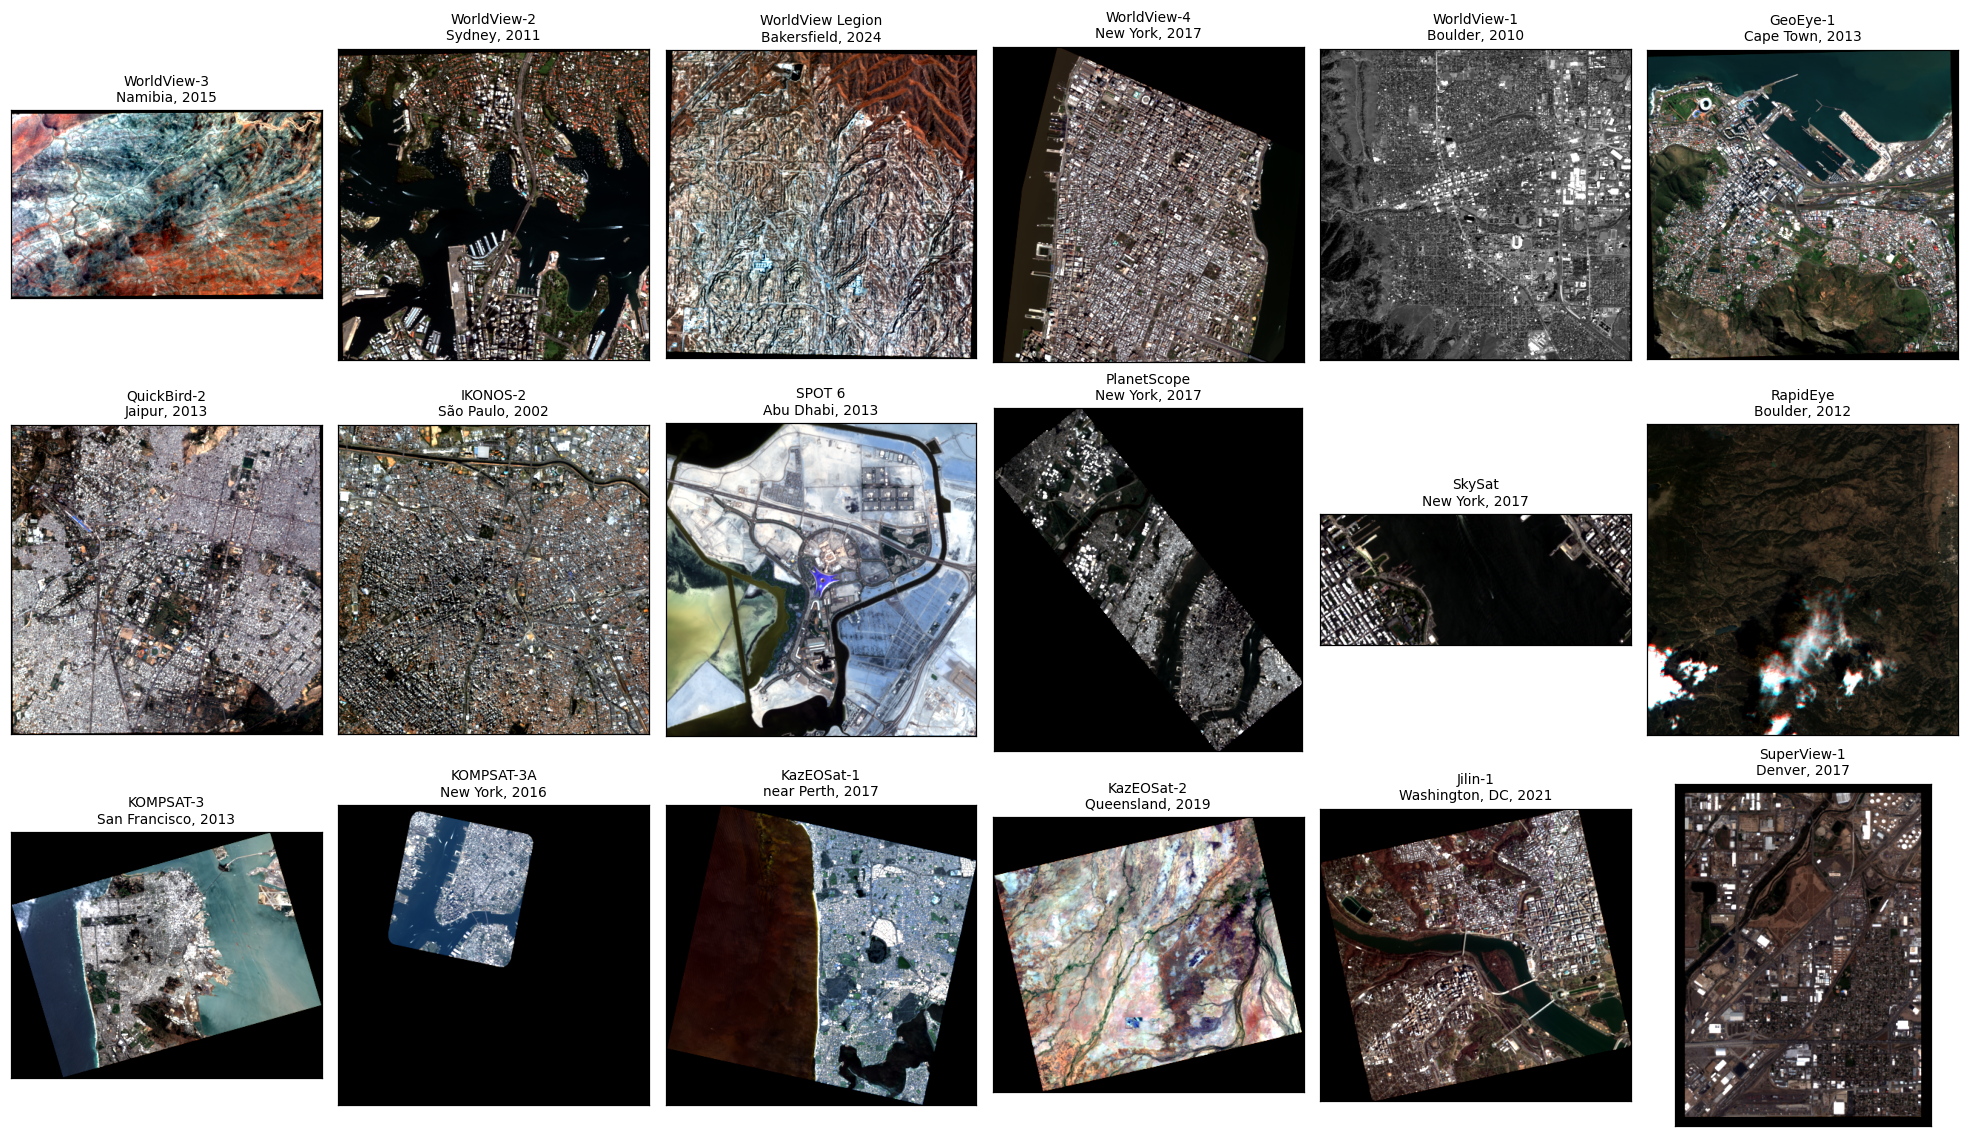

In [4]:
# Preview one real scene from each commercial sensor in Commercial_images/.
# Full scenes are huge (often hundreds of megabytes). We never load a whole
# file: each panel is a small natural-colour, or grey panchromatic, preview.
#
# 1. `read_preview` opens the GeoTIFF and asks rasterio to resample it on the
#    way in, so the long side of the array is `max_px` pixels (420 here).
# 2. `to_display` stretches each band from the 2nd to the 98th percentile.
#    That keeps dark water and bright ground both visible. Values outside the
#    scene (0 or the fill 65535) are painted black.
# 3. Band index tuples differ by product, because the files do not store bands
#    in the same order:
#    - 8-band WorldView: coastal, blue, green, yellow, red, ... so red/green/blue
#      are bands (5, 3, 2). Rasterio band numbers start at 1.
#    - 4-band files here: blue, green, red, near infrared, so red/green/blue
#      are bands (3, 2, 1).
#    - WorldView-1 has no colour bands, so we read the single panchromatic band.
#    - KOMPSAT stores red, green and blue in three separate files.
# 4. Draw the previews on a 3 × 6 grid. The Apollo Mapping entry is only a
#    pointer to a free poster; there is no local file for it.

COM = Path("../../../../Data/00_shared/data_remote_sensing/Commercial_images")

def read_preview(source, bands, max_px=420):  # read a small preview of a scene
    """Read red, green and blue, or one panchromatic band, with the long side at max_px.

    source is one GeoTIFF, or a list of single-band files already in red, green, blue order.
    KOMPSAT stores each band in its own file.
    """
    # A single path is one multi-band file. A list is one file per colour (KOMPSAT).
    paths = [source] if isinstance(source, Path) else list(source)
    with rasterio.open(paths[0]) as ds:  # open the first file to get its size
        # Scale factor from the full image down to a preview. out_hw is (rows, cols).
        scale = max(ds.height, ds.width) / max_px
        # preview size (rows, cols)
        out_hw = (max(1, round(ds.height / scale)), max(1, round(ds.width / scale)))
    if len(paths) == 1:  # one file holds all bands
        with rasterio.open(paths[0]) as ds:  # open it
            # Read only the requested band numbers, already resampled to out_hw.
            # Bilinear is a smooth preview; it is not the resampling you would use for analysis.
            data = ds.read(list(bands), out_shape=(len(bands), *out_hw),
                           resampling=rasterio.enums.Resampling.bilinear)
    else:
        planes = []  # one file per band
        for path in paths:  # every band file
            with rasterio.open(path) as ds:  # open it
                planes.append(ds.read(1, out_shape=out_hw,  # read it at preview size
                                       resampling=rasterio.enums.Resampling.bilinear))
        data = np.stack(planes)  # shape (3, rows, cols), already in red, green, blue order
    return data.astype("float32")  # as floats

def to_display(data):  # stretch an image for display
    """Stretch each band to the 2nd-98th percentile. A single band is drawn in grey."""
    image = np.zeros(data.shape[1:] + (3,), np.float32)  # an RGB image matplotlib can draw
    grey = data.shape[0] == 1  # one band means panchromatic: copy it into R, G and B
    for i in ([0] if grey else range(3)):  # one band (grey) or three (colour)
        band = data[0 if grey else i]  # the band to stretch
        # Ignore nodata. 0 is outside the scene; 65535 is a common integer fill value.
        valid = np.isfinite(band) & (band > 0) & (band < 65535)
        if int(valid.sum()) < 20:  # too few valid pixels: leave it black
            continue
        # Percentiles ignore the darkest and brightest 2%, which are usually outliers.
        lo, hi = np.percentile(band[valid], (2, 98))
        stretched = np.clip((band - lo) / max(hi - lo, 1), 0, 1)  # stretch to [0, 1]
        stretched[~valid] = 0  # black outside the scene
        if grey:  # single band:
            image[:] = stretched[..., None]  # copy it into all three channels
        else:
            image[..., i] = stretched  # colour channel
    return image  # the display image

# Each entry is (panel title, file or list of files, band numbers).
# Band numbers are 1-based, which is what rasterio expects.
# 8-band WorldView order is coastal, blue, green, yellow, red, so red/green/blue are bands 5, 3, 2.
# The 4-band files here are blue, green, red, near infrared, so red/green/blue are bands 3, 2, 1.
k3 = COM / "KOMPSAT/KOMPSAT3_SanFrancisco_7_13_2013_Bundle"
k3a = "KOMPSAT/K3A_20160824180916_07825_00026235_L1R"  # folder of the KOMPSAT-3A sample
scenes = [  # title, file(s) and band numbers of every sample scene
    # 8-band WorldView: pick red, green, blue out of coastal/blue/green/yellow/red/...
    ("WorldView-3\nNamibia, 2015",
     COM / "World_View/Namibia_WV3_SWIR_MS_Bundle_Sample/054265823020_01/054265823020_01_P001_MUL/15MAR16092139-M2AS-054265823020_01_P001.TIF", (5, 3, 2)),
    ("WorldView-2\nSydney, 2011",
     COM / "World_View/WV2_8band_Bundle_Sydney_Australia/052783824080_01_P001_MUL/11APR03001446-M2AS_R1C1-052783824080_01_P001.TIF", (5, 3, 2)),
    ("WorldView Legion\nBakersfield, 2024",
     COM / "World_View/Bakersfield_CA_8band_LG02/050246255010_01/050246255010_01_P001_MUL/24SEP22184516-M2AS-050246255010_01_P001.TIF", (5, 3, 2)),
    # 4-band blue, green, red, NIR.
    ("WorldView-4\nNew York, 2017",
     COM / "World_View/056965205010_01/056965205010_01_P001_MUL/17APR18154116-M2AS_R1C1-056965205010_01_P001.TIF", (3, 2, 1)),
    # Panchromatic only: one band, drawn in grey by to_display.
    ("WorldView-1\nBoulder, 2010",
     COM / "World_View/052987795060_01/052987795060_01_P001_PAN/10JUN22181146-P2AS-052987795060_01_P001.TIF", (1,)),
    ("GeoEye-1\nCape Town, 2013",
     COM / "GeoEye/053413654010_01/053413654010_01_P001_MUL/13JUL31084528-M2AS-053413654010_01_P001.TIF", (3, 2, 1)),
    ("QuickBird-2\nJaipur, 2013",
     COM / "Quickbird/053398467010_01/053398467010_01_P001_MUL/13SEP18045419-M2AS-053398467010_01_P001.TIF", (3, 2, 1)),
    ("IKONOS-2\nSão Paulo, 2002",
     COM / "IKONOS/po_1462947_0000000/po_1462947_bgrn_0000000.tif", (3, 2, 1)),
    ("SPOT 6\nAbu Dhabi, 2013",
     COM / "SPOT6_FerrariWorld_Bundle_9_16_2013/PROD_SPOT6_001/VOL_SPOT6_001_A/IMG_SPOT6_MS_001_A/IMG_SPOT6_MS_201309160638512_SEN_818325101_R1C1.TIF", (3, 2, 1)),
    ("PlanetScope\nNew York, 2017",
     COM / "Planetscops/20170620_134925_1_0c41/20170620_134925_1_0c41_3B_AnalyticMS.tif", (3, 2, 1)),
    ("SkySat\nNew York, 2017",
     COM / "SkySat/20170904_154355_ssc2d2_0018/20170904_154355_ssc2d2_0018_basic_analytic_dn.tif", (3, 2, 1)),
    ("RapidEye\nBoulder, 2012",
     COM / "RapidEye: Boulder CO/1357513_2012-07-21_RE5_3A_152735/1357513_2012-07-21_RE5_3A_152735.tif", (3, 2, 1)),
    # KOMPSAT: three single-band files already named in red, green, blue order. bands is unused.
    ("KOMPSAT-3\nSan Francisco, 2013",
     [k3 / f"K3_20130713205707_06169_16811282_L1G_{b}.tif" for b in "RGB"], None),
    ("KOMPSAT-3A\nNew York, 2016",
     [COM / f"{k3a}_{b}.tif" for b in "RGB"], None),
    ("KazEOSat-1\nnear Perth, 2017",
     COM / "KazEOSat/HR_1806010947429/DZZ-HR_20171122023359_038038_E115S31_2A_MS_HR_1806010947429/DZZ-HR_20171122023359_038038_E115S31_2A_MS_HR_1806010947429/imagery.tif", (3, 2, 1)),
    ("KazEOSat-2\nQueensland, 2019",
     COM / "KazEOSat/KM002a57MI_003_MUL_L1T.tif", (3, 2, 1)),
    ("Jilin-1\nWashington, DC, 2021",
     COM / "Jilin/Static_1m_GF03B_Washington_DC/JL1GF03B04_PMS_20210321224611_200044694_102_0007_001_L1_MSS/JL1GF03B04_PMS_20210321224611_200044694_102_0007_001_L1_MSS.tif", (3, 2, 1)),
    ("SuperView-1\nDenver, 2017",
     COM / "SuperView/SuperView_Sample_Denver_CO/1109180216001_01/SV1-02_20170804_L2A0000463770_1109180216001_01/SV1-02_20170804_L2A0000463770_1109180216001_01-MUX.tiff", (3, 2, 1)),
    # No local file: leave a note in the last panel instead of reading a URL.
    ("Apollo Mapping (poster sample)\nVarious locations",
     "https://apollomapping.com/download-free-poster", None),
]

fig, axes = plt.subplots(3, 6, figsize=(18, 10.4))  # 18 panels, one per scene
for ax, (title, source, bands) in zip(axes.ravel(), scenes):  # one panel per scene
    # The poster is a download link, not a GeoTIFF. Say so instead of calling rasterio.
    if isinstance(source, str) and 'apollomapping.com' in source:
        # placeholder text
        ax.text(0.5, 0.5, "See\nApollo Mapping\nPoster", ha='center', va='center', fontsize=10, color='gray')
        ax.set_title(title, fontsize=9)  # title
        ax.set_xticks([]); ax.set_yticks([])  # no ticks
        continue
    ax.imshow(to_display(read_preview(source, bands)))  # preview of the scene
    ax.set_title(title, fontsize=9)  # title
    ax.set_xticks([]); ax.set_yticks([])  # pixel coordinates are not map coordinates in this preview
plt.tight_layout(); plt.show()  # arrange and draw

## Hands-on: a commercial 8-band image

The GeoLattice data folder includes an 8-band Maxar (DigitalGlobe) multispectral image of a coastal
area of southern Bangladesh, taken in March, at 1.2 m. Its eight bands match the
WorldView-2/3 multispectral set (coastal, blue, green, yellow, red, red edge, NIR1, NIR2), and
it is delivered as **digital numbers** without the calibration file. A 9-class land-cover map
and labelled polygons come with it.


In [5]:
# Load the local 8-band commercial image of southern Bangladesh (March) and
# check what kind of file it is before we interpret the colours.
#
# 1. Point at the MARCH folder and name the eight bands in WorldView-2/3 order:
#    coastal, blue, green, yellow, red, red edge, NIR1, NIR2.
# 2. `rs.read` opens the GeoTIFF as an xarray DataArray with those band names,
#    plus the map coordinates stored in the file.
# 3. This file stores no-data as the integer 65536 (one more than a 16-bit
#    maximum, because the file is int32). `where` turns those pixels into NaN,
#    then we cast to float so later division (NDVI) is safe.
# 4. Print the coordinate system, the pixel size in metres, the shape, and the
#    ground size in kilometres. Then print the longitude and latitude of the
#    upper-left corner, and a small table of min / median / max digital numbers.

DG = Path("../../../../Data/00_shared/data_remote_sensing/Commercial_images/World_View/DG_MARCH")
WV_BANDS = ["coastal", "blue", "green", "yellow", "red", "rededge", "nir", "nir2"]   # WorldView-2/3 order
wv = rs.read(DG / "DG_MAR.tif", band_names=WV_BANDS)  # read the 8-band WorldView image with band names
wv = wv.where(wv < 65536).astype("float32")                     # 65,536 marks no-data in this int32 file
# rio.resolution() is (x size, y size). y is negative when rows run north to south, so we take abs.
print("CRS:", wv.rio.crs, "| pixel:", tuple(round(abs(r), 2) for r in wv.rio.resolution()), "m",
      "| size:", wv.shape, f"= {wv.rio.width * 1.2 / 1000:.1f} × {wv.rio.height * 1.2 / 1000:.1f} km")
# Reproject the northwest 2×2 pixels to longitude/latitude just to say where the scene sits.
# rio.bounds() is (left, bottom, right, top). Taking the first two values gives the
# southwest corner of that tiny crop, which is still the upper-left of the full scene.
lon, lat = rs.reproject(wv.isel(band=0, x=slice(0, 2), y=slice(0, 2)), "EPSG:4326").rio.bounds()[:2]
print(f"Upper-left corner near {lat:.3f}°N, {lon:.3f}°E")  # location of the upper-left corner
# to_dataset makes each band a variable, which is what the next cells index by name.
# drop spatial_ref so describe() summarises pixel values, not the CRS coordinate.
wv.to_dataset(dim="band").drop_vars("spatial_ref").to_dataframe().describe().loc[["min", "50%", "max"]].round(0)

CRS: EPSG:32646 | pixel: (1.2, 1.2) m | size: (8, 2827, 3132) = 3.8 × 3.4 km
Upper-left corner near 21.977°N, 90.183°E


,coastal,blue,green,yellow,red,rededge,nir,nir2
min,140.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0
50%,335.0,315.0,401.0,413.0,385.0,450.0,700.0,462.0
max,1663.0,2047.0,2047.0,2047.0,2047.0,2047.0,2047.0,2047.0


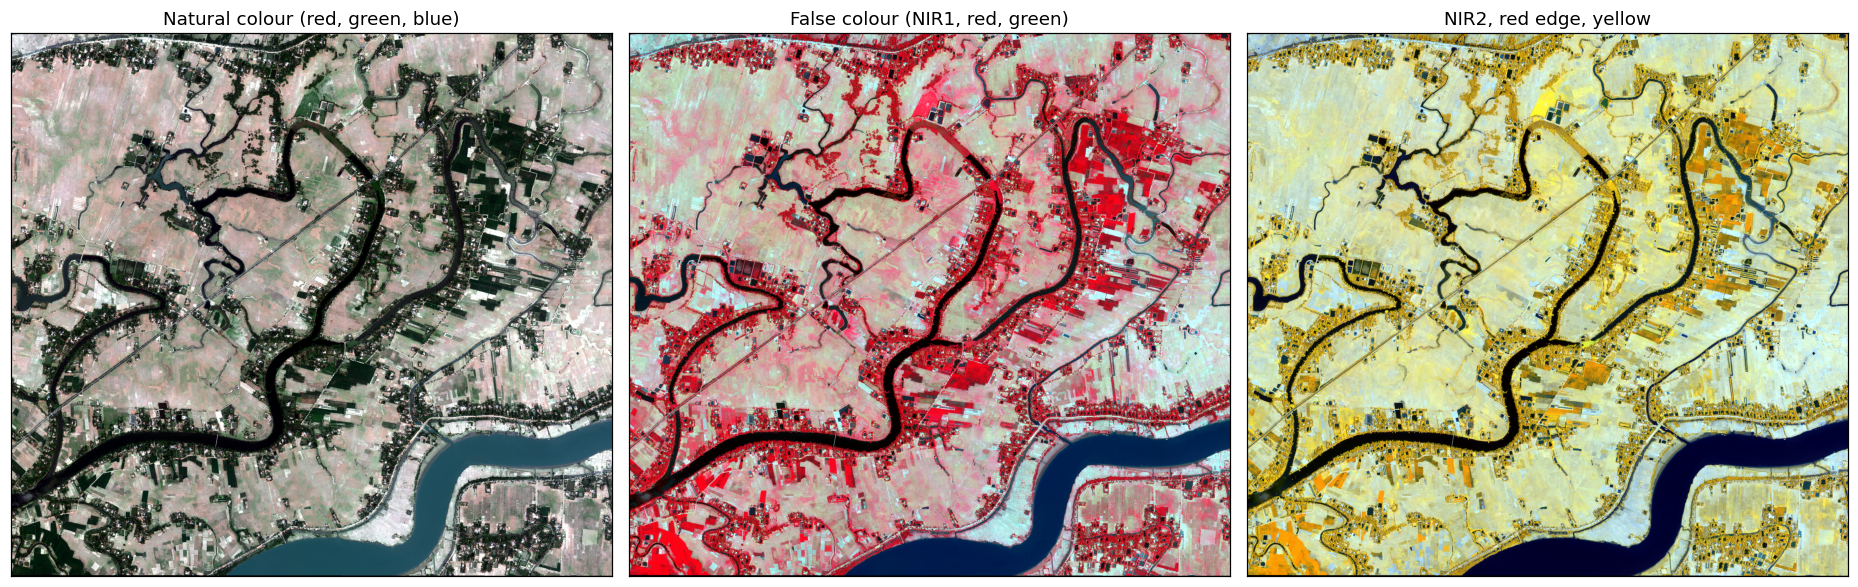

In [6]:
# Draw the same 8-band image three ways. `rs.viz.plot_rgb` picks three bands,
# stretches them, and paints them as red, green and blue on screen. The screen
# colours are a choice; they are not the wavelengths the sensor measured.
#
# Left: natural colour. Red light goes to the red channel, green to green, blue
# to blue, so the picture looks like a photograph.
# Middle: classic false colour. NIR1 (strongly reflected by leaves) is painted
# red, so growing vegetation comes out red and water stays dark.
# Right: a vegetation-contrast composite. NIR2, the red-edge band and yellow
# separate crops, trees and bare soil that look similar in natural colour.

ds = wv.to_dataset(dim="band")  # one variable per band name, so plot_rgb can ask for "nir" or "red"
fig, axes = plt.subplots(1, 3, figsize=(17, 5.4))  # three panels
# natural colour
rs.viz.plot_rgb(ds, ("red", "green", "blue"), ax=axes[0], title="Natural colour (red, green, blue)")
# false colour
rs.viz.plot_rgb(ds, ("nir", "red", "green"), ax=axes[1], title="False colour (NIR1, red, green)")
# NIR2, red edge, yellow
rs.viz.plot_rgb(ds, ("nir2", "rededge", "yellow"), ax=axes[2], title="NIR2, red edge, yellow")
for a in axes:  # for every panel
    a.set_xticks([]); a.set_yticks([])  # hide pixel indices; the map grid is the same in every panel
plt.tight_layout(); plt.show()  # arrange and draw

The scene is a dry-season landscape in the Ganges delta:

* **Water.** A large turbid river crosses the lower right. Narrow tidal channels meander through
  the image, and fishponds sit among the settlements.
* **Settlements.** Villages and homestead gardens with dense tree cover line the channels and
  embankments: dark green in natural colour and red in the false-colour image.
* **Fields.** Most fields are pale pink to grey, meaning fallow or harvested in March. Blocks of
  bright red in the false-colour image are fields with an actively growing dry-season crop.

At 1.2 m, field boundaries, single rows of trees, footpaths and the road crossing the image
diagonally are all distinct. In the third composite, built from bands that only some sensors
have (NIR2, red edge, yellow), vegetation is orange and the bare fields are pale.

The labelled sample points give each class's mean digital number in every band. Because these are DNs,
not reflectance, the curves can be compared with each other but not with the reflectance
signatures of notebook 07_01_00.


,sample points,coastal,blue,green,yellow,red,rededge,nir,nir2
Builtup,74,351.0,345.0,451.0,474.0,469.0,463.0,688.0,435.0
Crop,475,325.0,293.0,359.0,341.0,292.0,411.0,748.0,474.0
Fallow,76,345.0,333.0,431.0,462.0,453.0,470.0,698.0,465.0
Fallow - Plough,75,355.0,351.0,465.0,508.0,495.0,471.0,664.0,430.0
Fallow wet,1,335.0,314.0,399.0,401.0,371.0,413.0,644.0,416.0
Road,123,346.0,335.0,430.0,459.0,435.0,432.0,616.0,398.0
Vegetation,82,318.0,279.0,327.0,300.0,244.0,380.0,682.0,444.0
Water H,36,317.0,277.0,331.0,299.0,241.0,405.0,765.0,489.0
Water/River,115,321.0,286.0,332.0,311.0,258.0,225.0,257.0,138.0


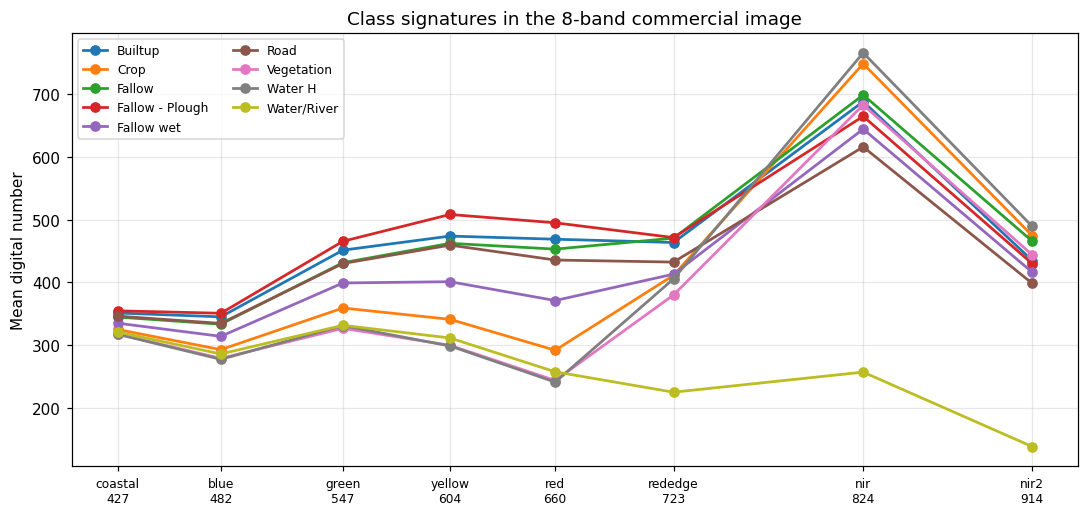

In [7]:
# Spectral signatures: the average digital number of each land-cover class in
# every band. A signature is the shape of that line. Water drops in the NIR;
# vegetation dips in the red and jumps at the red edge; bare soil stays bright
# and fairly flat. Those shapes are what a classifier uses.
#
# 1. Read the point shapefile and drop Class_ID 0 (unassigned duplicate points).
# 2. `rs.classify.extract_samples` looks up the pixel under each point and
#    returns a table of band values (X) and the class id of each point (y).
# 3. Average the digital numbers by class name, and add a column with how many
#    points went into each average.
# 4. Plot mean DN against the WorldView band-centre wavelengths (nm).

labels = gpd.read_file(DG / "Label_March.shp")
labels = labels[labels.Class_ID > 0]                              # Class_ID 0 rows are unassigned duplicates
X, y = rs.classify.extract_samples(ds, labels, "Class_ID")          # one row per point: the pixel under that point
# Class_ID -> a cleaned class name ("Water / River", "Crop", ...).
names = labels.drop_duplicates("Class_ID").set_index("Class_ID")["Class"].str.replace(r"\s+", " ", regex=True)
# Group the sample pixels by class name and take the mean DN in each of the 8 bands.
sig = X[WV_BANDS].groupby(pd.Series(y, index=X.index).map(names)).mean()
sig.insert(0, "sample points", pd.Series(y).map(names).value_counts())  # number of sample points of each class
display(sig.round(0))  # show the table

# Nominal WorldView-2/3 multispectral centres, same order as WV_BANDS.
centres = [427, 482, 547, 604, 660, 723, 824, 914]
fig, ax = plt.subplots(figsize=(10, 4.8))  # one panel
for cls, row in sig[WV_BANDS].iterrows():  # every class
    ax.plot(centres, row.values, marker="o", lw=1.8, label=cls)  # its mean spectrum
# band names and centre wavelengths on the x axis
ax.set_xticks(centres); ax.set_xticklabels([f"{b}\n{c}" for b, c in zip(WV_BANDS, centres)], fontsize=8)
# labels and title
ax.set_ylabel("Mean digital number"); ax.set_title("Class signatures in the 8-band commercial image")
ax.legend(fontsize=8, ncol=2); plt.tight_layout(); plt.show()  # legend, arrange and draw

The signatures show the classes the image can separate:

* **Water/River** is the only class whose NIR values fall far below the visible bands (NIR1
  257, NIR2 138).
* **Crop, Vegetation and "Water H"** show the vegetation shape: a dip in the red (240-290), a
  steep rise through the red edge and a NIR1 peak (680-765). "Water H" behaves like
  vegetation, not water. Together with its name, this suggests floating **water hyacinth**,
  which covers many ponds and channels in Bangladesh.
* **Built-up, fallow, ploughed land and roads** are bright and flat across the visible bands,
  with weaker NIR.

NIR2 is lower than NIR1 for every class. Two likely reasons: the NIR2 band spans the 940 nm
water-vapour absorption feature, and DNs of different bands are not on a common scale. Only
calibrated reflectance would show which effect dominates here.

Some labels rest on few samples ("Fallow wet" has a single point), so treat those curves with
caution.


## Hands-on: pixel size and mixed pixels

How much of this landscape could a coarser sensor see as pure pixels? The 1.2 m land-cover map
lets us answer exactly. We aggregate it to the pixel sizes of PlanetScope (3.6 m, the nearest
multiple of 1.2 m to 3 m), Sentinel-2 (10.8 m), Landsat (30 m) and MODIS (250.8 m), and count the
coarse pixels in which one class covers at least 90% of the area. Those are **pure** pixels;
the rest are **mixed**, and any classifier can only label them by their dominant class.


In [8]:
# How many pixels stay "pure" when we coarsen this 1.2 m land-cover map to the
# pixel size of a coarser sensor? A coarse pixel is pure when one class covers
# at least 90% of the fine cells inside it. Everything else is mixed: the
# satellite records a blend, and a classifier can only assign the dominant class.
#
# 1. Read the 1.2 m label raster, keep class codes 1-9, and snap it onto the
#    same grid as the WorldView image (nearest neighbour, so class codes are
#    not averaged into fake fractional classes).
# 2. `purity(L, f)` cuts the map into blocks of f × f fine pixels.
#    f = 1 is the original 1.2 m map, f = 3 is 3.6 m, f = 9 is 10.8 m,
#    f = 25 is 30 m, and f = 209 is 250.8 m (1.2 × 209).
# 3. For each block, find the class with the largest share. The block is pure
#    when that share is at least 90% and almost every fine cell is valid.
# 4. Build a table: percent of pure pixels overall, and the same percent inside
#    the crop, fallow, road and river pixels (classes 2, 3, 6 and 9).

lab = rs.read(DG / "Label_MARCH.tif").squeeze("band", drop=True)
# Finite and in 1..9: drop the raster's own nodata and any stray codes.
# reproject_match aligns the labels to the image grid without changing class integers.
lab = lab.where(np.isfinite(lab) & (lab >= 1) & (lab <= 9)).rio.reproject_match(wv.isel(band=0), resampling=rasterio.enums.Resampling.nearest)
L = lab.values  # the label array
classes = np.arange(1, 10)  # the nine class codes
# share of each class at 1.2 m
print("Land-cover shares at 1.2 m:", {names[c]: f"{np.nanmean(L == c) * 100:.1f}%" for c in classes})

def purity(L, f, threshold=0.9):  # which coarse pixels are pure for a block size f
    # Trim the edges so the array divides evenly into f × f blocks.
    H, W = (L.shape[0] // f) * f, (L.shape[1] // f) * f
    # reshape -> (n_block_rows, f, n_block_cols, f), then swap so each block is contiguous,
    # then flatten the f × f cells of each block into one length-f*f axis.
    blocks = L[:H, :W].reshape(H // f, f, W // f, f).swapaxes(1, 2).reshape(H // f, W // f, f * f)
    valid = np.isfinite(blocks).sum(-1)  # how many fine cells in the block are real labels
    # share[..., c] is the fraction of valid cells equal to class c.
    share = np.stack([(blocks == c).sum(-1) for c in classes], -1) / np.maximum(valid, 1)[..., None]
    ok = valid > 0.9 * f * f            # ignore blocks that are mostly outside the map
    dominant = share.argmax(-1) + 1     # class codes are 1-9; argmax is 0-8
    pure = share.max(-1) >= threshold   # True where one class covers >= 90%
    return ok, pure, dominant  # the three arrays

rows = []  # one row per simulated sensor
# block sizes that mimic each sensor's pixel size
for name, f in [("Commercial VHR (1.2 m)", 1), ("PlanetScope-like (3.6 m)", 3), ("Sentinel-2-like (10.8 m)", 9),
                ("Landsat-like (30 m)", 25), ("MODIS-like (250.8 m)", 209)]:
    ok, pure, dom = purity(L, f)  # purity at this block size
    # number of coarse pixels and the share that is pure
    row = {"sensor": name, "pixels": int(ok.sum()), "pure pixels (%)": round(float(pure[ok].mean()) * 100, 1)}
    for c in [2, 3, 6, 9]:                                          # crop, fallow, road, river
        m = ok & (dom == c)  # coarse pixels whose dominant class is c
        # purity per dominant class
        row[f"pure, {names[c]}"] = round(float(pure[m].mean()) * 100, 1) if m.any() else np.nan
    rows.append(row)  # store the row
mix = pd.DataFrame(rows).set_index("sensor")  # as a table
mix  # show it

Land-cover shares at 1.2 m: {'Builtup': '1.8%', 'Crop': '36.4%', 'Fallow': '21.5%', 'Fallow - Plough': '4.8%', 'Fallow wet': '1.6%', 'Road': '6.8%', 'Vegetation': '14.3%', 'Water H': '0.8%', 'Water/River': '11.7%'}


,pixels,pure pixels (%),"pure, Crop","pure, Fallow","pure, Road","pure, Water/River"
sensor,,,,,,
Commercial VHR (1.2 m),8832849,100.0,100.0,100.0,100.0,100.0
PlanetScope-like (3.6 m),980441,42.1,45.4,35.8,7.4,78.5
Sentinel-2-like (10.8 m),108413,30.2,34.6,26.6,1.5,59.6
Landsat-like (30 m),14058,15.2,15.8,12.5,0.0,43.2
MODIS-like (250.8 m),182,0.0,0.0,0.0,NaN,0.0


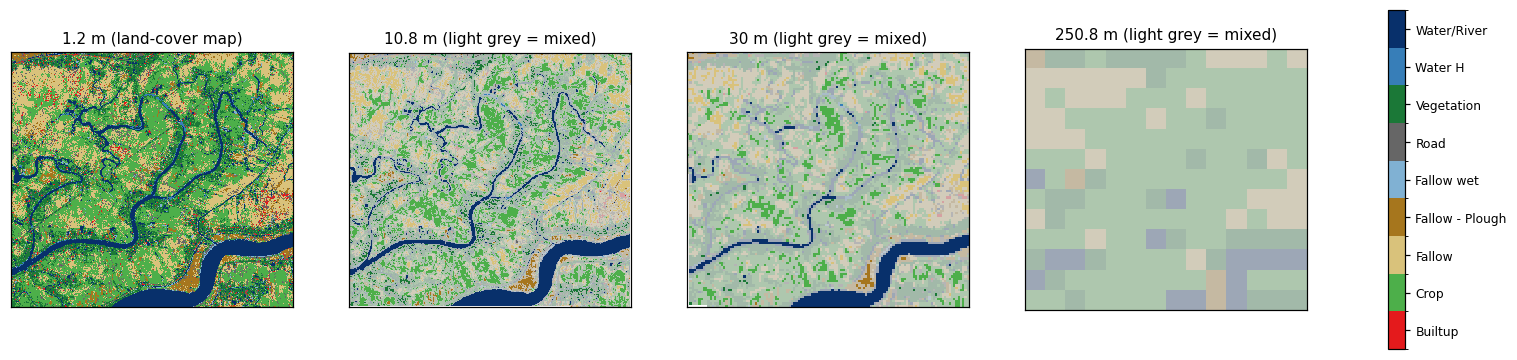

In [11]:
# Map the dominant class at four pixel sizes, and paint mixed pixels light grey
# so you can see where a coarser sensor stops resolving this landscape.
#
# At 1.2 m every labelled cell is shown in its own class colour (the map is the
# reference, so nothing is called mixed). At 10.8 m, 30 m and 250.8 m we reuse
# `purity` from the previous cell: the colour is still the dominant class, but
# any block below the 90% rule is covered with light grey.

from matplotlib.colors import ListedColormap, BoundaryNorm
# Nine class colours, in Class_ID order 1..9. BoundaryNorm puts each integer in its own bin.
cmap = ListedColormap(["#e41a1c", "#4daf4a", "#d9c27b", "#a6761d", "#80b1d3", "#666666", "#1b7837", "#377eb8", "#08306b"])
norm = BoundaryNorm(np.arange(0.5, 10.5), cmap.N)  # map class codes 1-9 to colours
grey = ListedColormap(["#d0d0d0"])
fig, axes = plt.subplots(1, 4, figsize=(19, 5))  # four panels
# four pixel sizes
for a, (title, f) in zip(axes, [("1.2 m", 1), ("10.8 m", 9), ("30 m", 25), ("250.8 m", 209)]):
    # f = 1: show the original labels. f > 1: one colour per coarse block.
    ok, pure, dom = purity(L, f) if f > 1 else (np.isfinite(L), np.ones_like(L, bool), L)
    show = np.where(ok, dom, np.nan).astype(float)  # NaN outside the map, so those cells stay blank
    a.imshow(show, cmap=cmap, norm=norm, interpolation="nearest")  # the dominant class of each coarse pixel
    if f > 1:  # coarse pixel sizes only
        # Second image, drawn on top: grey only where the block exists and is mixed.
        a.imshow(np.where(ok & ~pure, 1.0, np.nan), cmap=grey, alpha=0.75, interpolation="nearest")
    a.set_title(f"{title}" + (" (light grey = mixed)" if f > 1 else " (land-cover map)"), fontsize=10)  # title
    a.set_xticks([]); a.set_yticks([])  # no ticks
# one colour bar for all panels
cb = fig.colorbar(plt.cm.ScalarMappable(norm=norm, cmap=cmap), ax=axes, ticks=classes, shrink=0.8)
cb.ax.set_yticklabels([names[c] for c in classes], fontsize=8)  # class names on it
plt.show()  # draw

This landscape is fine-grained: fields, homestead tree belts, channels and roads are a few
metres to a few tens of metres across. Even at 3.6 m, 58% of pixels are mixed. At Sentinel-2's
10.8 m only 30% are pure, at Landsat's 30 m 15%, and at MODIS scale none: every 250 m pixel
blends several classes.

Narrow features disappear first. Roads are 7% pure at 3.6 m, 1.5% at 10.8 m and 0% at 30 m.
The river is the most robust class, still 43% pure at 30 m, because its main channel is wide.

Two caveats. The 1.2 m map is a classification supplied with the image, not field truth. The
blocks are exact aggregates rather than real sensor footprints, which also blur across pixel
edges (MTF), so real sensors look slightly worse. The lesson for sensor choice: in smallholder
landscapes like this one, 10-30 m data describe *proportions* of land cover per pixel rather
than individual fields.


## Hands-on: open Sentinel-2 and Landsat over the same place (live)

Open archives cover this site too. `get_images` searches Microsoft Planetary Computer for the
clearest March scene from Sentinel-2 L2A and Landsat 8/9 Collection 2 Level-2, clips red and
near infrared to the commercial image footprint (`mode="clip"`), and we compare NDVI at the
three resolutions. The dates differ from the commercial image, so compare detail, not crops.


In [13]:
# Read the clearest open scene over this same footprint and compare it with
# the commercial image. Scenes already downloaded into ../../../../Data/08_remote_sensing/08_02_optical/optical_compare are
# read from disk. A scene that is not there yet is downloaded, which needs the
# network; offline, the missing scene is skipped and the rest of the notebook
# still runs.
#
# 1. Test the catalogue, and turn the WorldView image bounds into a longitude /
#    latitude box. That box is the search area.
# 2. Ask `get_images` for March 2024, cloud cover under 10%, and only the
#    clearest scene. `bands=["red", "nir"]` and `mode="clip"` mean we download
#    two bands, already cut to the box, not the whole satellite scene.
#    One search is Sentinel-2 L2A (10 m). The other is Landsat Collection 2
#    Level-2 (30 m).
# 3. `rs.optical.scale` turns the stored integers into surface reflectance.
#    Sentinel-2 L2A also needs a small offset (`boa_offset=-1000`) before the
#    usual scale factor; Landsat's scale is applied with the default.
# 4. NDVI = (NIR − red) / (NIR + red). Store the date, the scene cloud
#    percent and the NDVI grid so the next cell can plot them.

from datetime import date
import json  # read the scene metadata (item.json)

from geolattice.network import is_online  # internet check
from geolattice.rsense.get_images import get_images  # one-call search and download

# The notebook's data folder: ../../../../Data/08_remote_sensing/08_02_optical/ next to this notebook, found from here or from the repository root.
DATA = next((p for p in (Path("Data/08_remote_sensing/08_02_optical"), Path("../../../../Data/08_remote_sensing/08_02_optical"))
             if p.is_dir()), Path("../../../../Data/08_remote_sensing/08_02_optical"))

def local_scenes(folder, files=()):
    """Scene folders already downloaded under `folder` that contain every file in `files`."""
    folder = Path(folder)
    if not folder.is_dir():  # nothing downloaded yet
        return []
    return sorted(p for p in folder.iterdir() if p.is_dir() and all((p / f).exists() for f in files))


ONLINE = is_online(rs.access.CATALOGS["planetary-computer"])  # can Planetary Computer be reached?
bbox = tuple(wv.rio.transform_bounds("EPSG:4326"))  # (west, south, east, north) in degrees
# status and AOI
print("Planetary Computer reachable:", ONLINE, "| AOI (lon/lat):", tuple(round(v, 4) for v in bbox))

OUT = DATA / "optical_compare"  # where the clipped GeoTIFFs are stored
open_imgs = {}  # NDVI and metadata per open sensor
t0 = time.perf_counter()  # start the timer
# key is the panel name, sensor is what rs.optical.scale expects, kwargs go to get_images.
jobs = [
    ("Sentinel-2 L2A, 10 m", "sentinel2", dict(
        out=OUT / "s2", dates=("2024-03-01", "2024-03-31"), collection="sentinel-2-l2a",
    )),
    ("Landsat C2 L2, 30 m", "landsat", dict(
        out=OUT / "ls", dates=("2024-03-01", "2024-03-31"), collection="landsat-c2-l2",
    )),
]
for key, sensor, kwargs in jobs:  # every sensor
    local = local_scenes(kwargs["out"], ["red.tif", "nir.tif", "item.json"])  # scenes already on disk
    if local:  # downloaded before: read it from the local drive
        scene_dir = local[0]  # the scene folder
        props = json.loads((scene_dir / "item.json").read_text())["properties"]  # its catalogue record
        scene = {"id": scene_dir.name, "datetime": props.get("datetime"), "cloud": props.get("eo:cloud_cover")}
        print(f"{key}: reading {scene_dir}")  # where it comes from
    elif ONLINE:  # not on disk yet: download it
        saved = get_images(  # download the clearest March scene, clipped to the AOI
            bbox=bbox, source="planetary", cloud=10, clearest=True,
            bands=["red", "nir"], mode="clip", quiet=True, **kwargs,
        )
        if not saved.scenes:  # nothing found
            print(f"{key}: no scene"); continue  # skip this sensor
        # saved.scenes[0] is the catalogue record (id, date, cloud). The pixels
        # are GeoTIFFs in the first subfolder of saved.out.
        scene, scene_dir = saved.scenes[0], next(p for p in saved.out.iterdir() if p.is_dir())
    else:  # offline and not on disk
        print(f"{key}: offline and not downloaded yet, skipped"); continue
    ds = xr.Dataset({  # red and NIR as a Dataset
        "red": rs.read(scene_dir / "red.tif").squeeze("band", drop=True),
        "nir": rs.read(scene_dir / "nir.tif").squeeze("band", drop=True),
    })
    # Sentinel-2 surface reflectance is stored with an offset; Landsat is not.
    scaled = rs.optical.scale(ds, sensor=sensor, boa_offset=-1000 if sensor == "sentinel2" else None)
    ndvi = (scaled.nir - scaled.red) / (scaled.nir + scaled.red)  # NDVI from reflectance
    # acquisition date
    when = date.fromisoformat(str(scene["datetime"])[:10]) if scene.get("datetime") else None
    cloud = scene.get("cloud")  # scene cloud cover
    open_imgs[key] = {"date": when, "cloud": cloud, "ndvi": ndvi}  # store the result
    # report it
    print(f"{key}: {scene['id']}, {when}, scene cloud {float(cloud or 0):.1f}%, AOI grid {tuple(ndvi.shape)}")
print(f"Reading and downloading took {time.perf_counter() - t0:.0f} s")  # run time

Planetary Computer reachable: True | AOI (lon/lat): (90.1828, 21.9465, 90.2198, 21.9777)
1 scene(s), 2 band file(s) to fetch


bands: 100%|██████████| 2/2 [00:02<00:00,  1.16s/it]


Sentinel-2 L2A, 10 m: S2B_MSIL2A_20240311T042659_R133_T46QBK_20240311T081942, 2024-03-11, scene cloud 0.0%, AOI grid (354, 389)
1 scene(s), 2 band file(s) to fetch


bands: 100%|██████████| 2/2 [00:01<00:00,  1.35it/s]

Landsat C2 L2, 30 m: LC08_L2SP_137045_20240309_02_T1, 2024-03-09, scene cloud 0.1%, AOI grid (118, 131)
Search and read took 7 s


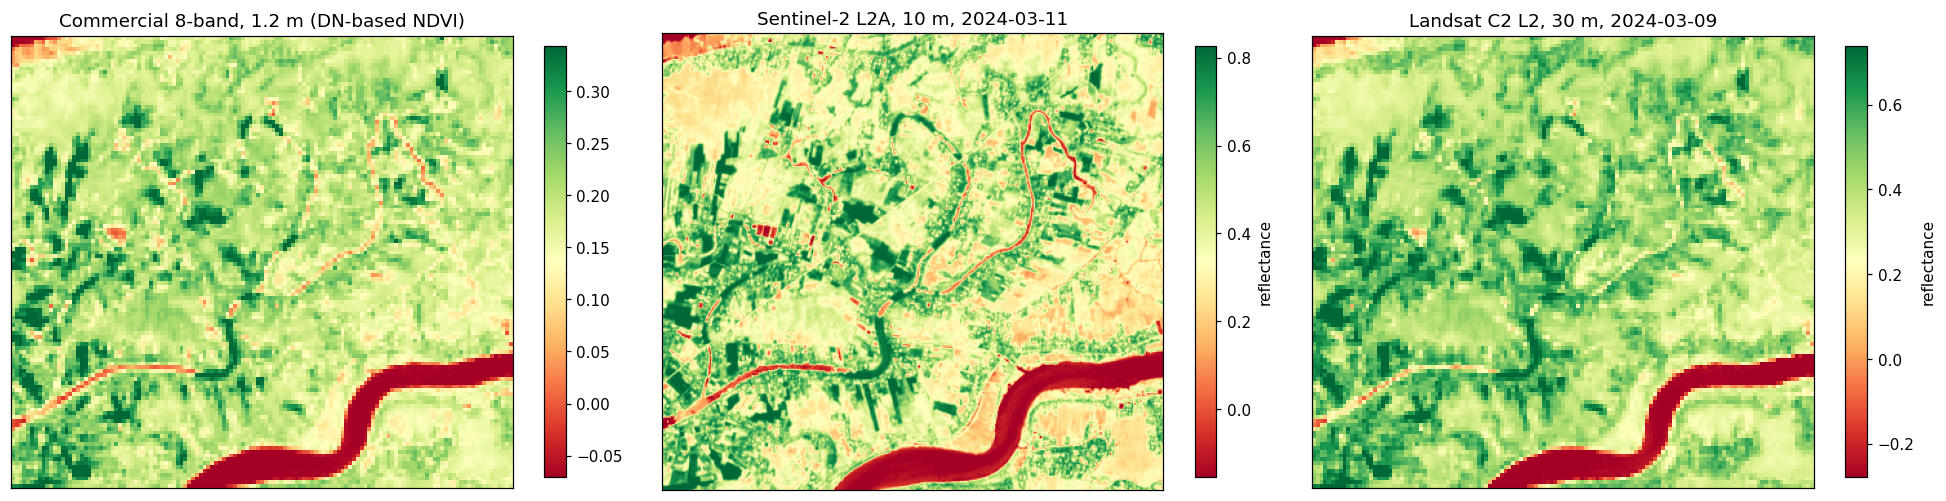

,date,pixels in AOI,median NDVI
"Sentinel-2 L2A, 10 m",2024-03-11,137706,0.396
"Landsat C2 L2, 30 m",2024-03-09,15458,0.411


In [14]:
# Put the commercial NDVI next to the open NDVI from the previous cell.
# The point of the figure is spatial detail, not the crop calendar: the open
# scenes are a different March than the commercial image.
#
# The commercial NDVI is computed from digital numbers, not reflectance. DN in
# this file is roughly proportional to radiance, so the *pattern* (high over
# leaves, low over water) is meaningful, but the numeric NDVI is not comparable
# to the scaled Sentinel-2 and Landsat values. Those two are real reflectance NDVI.
# If the download was skipped, only the commercial panel is drawn.

# `ds` is the 8-band WorldView dataset from the composite cell (wv.to_dataset).
# The download cell also uses the name `ds` inside its loop. If that cell has
# already run, re-run the composite cell first so this line still sees the
# commercial bands, not the last Landsat or Sentinel-2 scene.
wv_ndvi = (ds["nir"] - ds["red"]) / (ds["nir"] + ds["red"])          # DN-based: relative values only
# One panel for the commercial image, then one panel per open scene that was actually downloaded.
panels = [("Commercial 8-band, 1.2 m (DN-based NDVI)", wv_ndvi)] + [(f"{k}, {v['date']}", v["ndvi"]) for k, v in open_imgs.items()]
fig, axes = plt.subplots(1, len(panels), figsize=(6 * len(panels), 5.2))  # one panel per image
axes = np.atleast_1d(axes)  # a single panel comes back as one Axes, not a list
for a, (title, da) in zip(axes, panels):  # every panel
    rs.viz.plot_raster(da, ax=a, cmap="RdYlGn", title=title)  # brown = low NDVI, green = high NDVI
    a.set_xticks([]); a.set_yticks([])  # no ticks
plt.tight_layout(); plt.show()  # arrange and draw
if open_imgs:  # only if open scenes were downloaded
    # Date, how many pixels fell inside the AOI, and the median NDVI of those pixels.
    display(pd.DataFrame({k: {"date": v["date"], "pixels in AOI": int(v["ndvi"].notnull().sum()),
                              "median NDVI": round(float(v["ndvi"].median()), 3)} for k, v in open_imgs.items()}).T)

The open archives had cloud-free March scenes for this site: Sentinel-2B on 11 March 2024 (0%
scene cloud) and Landsat 8 on 9 March 2024 (0.1%). Finding them and reading only the area of
the commercial image took about 10 seconds. The same 3.8 × 3.4 km is covered by:

| Sensor | Grid | Pixels |
|---|---|---|
| Commercial | 3,132 × 2,827 | 8.8 million |
| Sentinel-2 | 377 × 340 | 128,000 |
| Landsat | 127 × 114 | 14,000 |

Sentinel-2 still shows individual fields, tree belts and the main channels. Landsat shows the
river and the broad pattern of green and fallow land, but the narrow channels and roads have
merged into their surroundings, exactly as the mixed-pixel analysis predicted.

The two open sensors, two days apart, agree on the median NDVI (0.398 and 0.413) because both
are surface reflectance. The commercial NDVI covers a lower, narrower range (about −0.15 to
0.55) because it is computed from uncalibrated DNs that still contain atmospheric path
radiance. Its pattern is valid, but its values cannot be compared with the open data until the
image is calibrated. The images are also from different years, so field-by-field differences
are expected.


## Summary, exercises and references

**Key ideas**

- Optical sensors are passive: they record reflected sunlight in the visible, NIR and SWIR, and
  need daylight and clear skies.
- Pushbroom and frame designs dominate modern sensors; panchromatic bands give detail,
  multispectral and hyperspectral bands give identity.
- Pixel size, swath and revisit trade off against each other; off-nadir viewing, MTF and SNR
  decide what a pixel really shows.
- Open data (Landsat, Sentinel-2, MODIS, HLS) are free, calibrated, global and long; commercial
  data add sub-metre detail, tasking and daily revisits at a cost and with licence limits.
- Analysis-ready surface reflectance is the starting point; commercial DNs need their
  calibration metadata.

**What the data showed**

- The 8-band commercial image, 11-bit DNs at 1.2 m, separates water, vegetation (including
  probable water hyacinth) and bright bare or built surfaces. Its yellow, red-edge and NIR2 bands
  add information that broad 4-band sensors lack.
- In this fragmented delta landscape only 30% of 10 m pixels and 15% of 30 m pixels are pure;
  narrow roads vanish entirely at 30 m.
- Free Sentinel-2 and Landsat scenes of the same site, two days apart, agree on median NDVI
  (0.40 and 0.41); uncalibrated commercial DNs do not give comparable values.

**Exercises**

1. Compute the GSD of a sensor with 10 µm detectors and a 1.0 m focal length at 500 km
   altitude. What is its across-track GSD at 30° off nadir?
2. Recompute the mixed-pixel table with a purity threshold of 75% instead of 90%. Which
   classes change most?
3. Using the class signatures of the *Hands-on: a commercial 8-band image* section, which single band ratio best separates "Crop" from
   "Vegetation"? Test it with a histogram.
4. (Online) Repeat the *Hands-on: open Sentinel-2 and Landsat over the same place (live)* section for a wet-season month (July or August). How many clear Sentinel-2
   scenes are there, and why?
5. Write a short data plan for monitoring rice fields in a 50 × 50 km district for three
   seasons: which open and commercial data would you use, at what dates, and why?

**References**

- Lillesand, T., Kiefer, R.W. & Chipman, J. (2015). *Remote Sensing and Image Interpretation*, 7th ed. Wiley.
- Jensen, J.R. (2016). *Introductory Digital Image Processing: A Remote Sensing Perspective*, 4th ed. Pearson.
- Schowengerdt, R.A. (2007). *Remote Sensing: Models and Methods for Image Processing*, 3rd ed. Academic Press.
- Wulder, M.A. et al. (2019). Current status of Landsat program, science, and applications. *Remote Sensing of Environment* 225, 127-147.
- Drusch, M. et al. (2012). Sentinel-2: ESA's optical high-resolution mission for GMES operational services. *Remote Sensing of Environment* 120, 25-36.
- Claverie, M. et al. (2018). The Harmonized Landsat and Sentinel-2 surface reflectance data set. *Remote Sensing of Environment* 219, 145-161.
- Operator specifications: USGS Landsat Missions, ESA Sentinel-2 User Guide, Maxar, Airbus Defence and Space, and Planet product documentation.

**Next:** Notebook 07_02_03 starts with MODIS, the daily global workhorse.
